# M13.3b / M13.4a — Evaluación G3 frente a G1 y HIP-CONTEXTO (val)

Entradas (solo lectura), en `<data_root>/results/M13_3/<tag>/`: `val_predictions_embeddings.npz`, `train40k_predictions.npz`
y `history.npz` para G1 (`M13_3a_R2_s123`, `M13_3a_R3_s124`) y G3 (`M13_3b_G3_s123`, `M13_3b_G3_s124`, `M13_4a_G3_s123`);
npz de val de M11 final G1 (hash fijado). Escalador train-only y split del contrato congelado G1 (`g1_npe_contract.load_contract`,
config M11), el mismo en G1 y G3. Del HDF5 trainio de G3 solo se leen `mass_1, mass_2, spin_1z, spin_2z, target_network_snr,
file_group_id` en las filas de val. Ni X, ni cal ni test.

Convenciones: etiquetas [chirp_mass, total_mass, chi_eff]; unidades físicas; residuo r = f − θ; “pendiente θ sobre f” = OLS de la
verdad sobre la predicción. Épocas 0-based. “Media G1” = media de R2/R3; “media G3” = media de M13_3b s123/s124 (media de las
métricas por modelo, no de las predicciones). Los IC son bootstrap emparejado por filas de val: miden **muestreo de filas, no
variación entre semillas**. Solo validación: no es una evaluación en test.

Salida única: `<data_root>/results/M13_3/M13_3b_4a_evaluation_summary.json` (modo `'x'`; aborta si existe).

In [1]:
import json
import sys
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root, resolve_processed_artifact
# Read-only reuse: pinned G1 contract, exact C3 implementation of M12.5.3, tau30/f220 of M13.1.
from scripts.m12.g1_npe_contract import PINNED
from scripts.m12.m12_5_3_posthoc_check import (
    ALPHAS, DATASET, FAMILY_ALPHA, LABELS, MARGIN_FRAC, bootstrap_means, decide, digest,
    load_contract, npz_to_physical, require, ridge_paths, select_inner, slope_row)
from scripts.m13.m13_1_diagnostics import chirp_mass, f220_hz, tau_newtonian

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
G3_CONFIGS = ['train_m13_3b_G3_s123.json', 'train_m13_3b_G3_s124.json', 'train_m13_4a_G3_s123.json']
cfg_g3 = [json.loads((ROOT / 'configs/experiments/m13' / n).read_text()) for n in G3_CONFIGS]
require(all(c['dataset'] == cfg_g3[0]['dataset'] for c in cfg_g3), 'G3 configs differ in their dataset block')
require(all(cfg_g3[0]['dataset'][k] == cfg['dataset'][k] for k in ('split_file', 'label_stats_file')),
        'G3 configs do not use the M11 split / train-only label stats')
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=cfg_g3[0]['dataset']['dataset_id'],
                                   file_name=cfg_g3[0]['dataset']['dataset_file'])
M11_NPZ = DATA_ROOT / 'results' / DATASET / 'm11_final_G1_500k_val_predictions_embeddings.npz'
M13_DIR = DATA_ROOT / 'results' / 'M13_3'
TAGS = {'R2': 'M13_3a_R2_s123', 'R3': 'M13_3a_R3_s124', 'G3_s123': 'M13_3b_G3_s123',
        'G3_s124': 'M13_3b_G3_s124', '4a_s123': 'M13_4a_G3_s123'}
NEW = list(TAGS)
MODELS = ['M11'] + NEW
G1, G3, H4A = ['R2', 'R3'], ['G3_s123', 'G3_s124'], '4a_s123'  # G1 seed pair, G3 seed pair, M13.4a
DATASET_OF = {m: 'G1' if m in G1 else 'G3' for m in NEW}
SUMMARY_PATH = M13_DIR / 'M13_3b_4a_evaluation_summary.json'
M13_3A_SUMMARY = M13_DIR / 'M13_3a_evaluation_summary.json'

# Fixed settings (prompt M13.3b/M13.4a).
Y_RTOL = 1e-5                     # y equality: |dy| <= rtol*|y| + rtol*y_std (float32 round trip)
N_BOOT = 2000
SEED_GLOBAL, SEED_BAND, SEED_TAU = 136001, 136002, 136003
EPOCH_MARK, EPOCH_END = 64, 79
C3_N_BOOT, C3_SEED = 2000, 125301  # M12.5.3 protocol
MIN_GROUP_N = 200                  # flag only (as in M13.1); groups are never dropped
SNR_EDGES = np.linspace(10.0, 25.0, 6)          # 5 equal-width bins, last closed
MTOT_EDGES = [10.0, 30.0, 50.0, 80.0, 120.0, 180.0]  # last bin closed
META = ['mass_1', 'mass_2', 'spin_1z', 'spin_2z', 'target_network_snr', 'file_group_id']
COLORS = {'M11': 'k', 'R2': 'tab:orange', 'R3': 'tab:green', 'G3_s123': 'tab:blue', 'G3_s124': 'tab:purple',
          '4a_s123': 'tab:red', 'G1': 'tab:orange', 'G3': 'tab:blue'}

require(not SUMMARY_PATH.exists(), f'Summary already exists: {SUMMARY_PATH}')
print(DATA_ROOT, G3_H5, sep='\n')

/data/vserrano/cbc_pe_data
/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_G3_band1024_w16_500k_trainio.h5


## 0. Integridad
SHA256 de cada npz (M11 contra el hash fijado del contrato; R2/R3 contra el resumen de M13_3a si existe); contrato G1; `y_mean/y_std`
de cada npz (los mismos tensores que guarda el checkpoint en `train_m13_3.py`) iguales al escalador train-only de M11; `dataset_path`
del npz = HDF5 de G1 o de G3 según el modelo; mismas `idx` de val y misma `y` en los 6 modelos (G1 y G3 comparten fuentes);
metadatos de val del HDF5 G3 reproducen `y`. Cualquier fallo aborta. Filas ordenadas por `idx` ascendente.

In [2]:
paths, splits, c_mean, c_std, identity = load_contract(DATA_ROOT)
files = {'M11_val': M11_NPZ}
for m, tag in TAGS.items():
    for kind, name in (('val', 'val_predictions_embeddings.npz'), ('train40k', 'train40k_predictions.npz'),
                       ('history', 'history.npz')):
        files[f'{m}_{kind}'] = M13_DIR / tag / name
missing = [str(p) for p in list(files.values()) + [G3_H5] if not p.exists()]
require(not missing, f'Missing inputs: {missing}')
sha = {k: digest(p) for k, p in files.items()}

checks = ['frozen G1 contract (g1_npe_contract.load_contract)', 'G3 configs share dataset block, M11 split and stats']
def check(ok, name):
    require(bool(ok), 'Check failed: ' + name)
    checks.append(name)


check(sha['M11_val'] == PINNED['baseline'], 'M11 val npz SHA256 equals pinned baseline')
if M13_3A_SUMMARY.exists():
    prev = json.loads(M13_3A_SUMMARY.read_text())['inputs']
    for k in [k for k in files if k.split('_')[0] in G1]:
        check(k in prev and prev[k]['sha256'] == sha[k], f'{k}: SHA256 equals M13_3a summary')
else:
    print('M13_3a summary not found: R2/R3 hashes not cross-checked')
EXPECTED_H5 = {'G1': paths['dataset_file'].name, 'G3': G3_H5.name}


def load_pred(path, split, name, dataset=None):
    # model_config / input_normalization are object arrays and are never accessed.
    with np.load(path, allow_pickle=False) as a:
        f, y = (a[k].astype(np.float64) for k in (f'pred_{split}', f'y_{split}'))
        emb = a[f'emb_{split}'].astype(np.float64)
        idx = a[f'idx_{split}'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        split_name = Path(str(a['split_path'])).name
        ds_name = Path(str(a['dataset_path'])).name if 'dataset_path' in a.files else None
        stats_name = Path(str(a['label_stats_path'])).name if 'label_stats_path' in a.files else None
    n = len(idx)
    check(f.shape == y.shape == (n, 3) and emb.shape[0] == n, f'{name}: shapes')
    check(label_names == LABELS, f'{name}: label order {LABELS}')
    check(split_name == paths['split_file'].name, f'{name}: split_path is the pinned split file')
    # y_mean/y_std are written from the same arrays stored in the checkpoint (train_m13_3.py).
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{name}: npz/checkpoint y_mean/y_std equal M11 train-only label stats')
    if dataset is not None:
        check(ds_name == EXPECTED_H5[dataset], f'{name}: dataset_path is the {dataset} HDF5')
        check(stats_name == paths['label_stats_file'].name, f'{name}: label_stats_path is the M11 stats file')
    check(len(np.unique(idx)) == n, f'{name}: idx without duplicates')
    check(all(np.isfinite(v).all() for v in (f, y, emb)), f'{name}: finite values')
    y, f, units = npz_to_physical(y, f, c_mean, c_std)
    check(np.all(np.abs(f.mean(0) - y.mean(0)) < 0.1 * c_std), f'{name}: pred in units of y ({units})')
    o = np.argsort(idx)
    return dict(f=f[o], y=y[o], emb=emb[o], idx=idx[o], units=units)


val = {'M11': load_pred(M11_NPZ, 'val', 'M11 val')}
tr40 = {}
for m in NEW:
    val[m] = load_pred(files[f'{m}_val'], 'val', f'{m} val', DATASET_OF[m])
    tr40[m] = load_pred(files[f'{m}_train40k'], 'train', f'{m} train40k', DATASET_OF[m])

IDX, Y = val['M11']['idx'], val['M11']['y']
check(np.array_equal(IDX, splits['val']), 'M11 idx_val equals val membership')
for m in NEW:
    check(np.array_equal(val[m]['idx'], IDX), f'{m}: same val idx as M11')
    dy = np.abs(val[m]['y'] - Y)
    print(f'{m}: max |y - y_M11| =', dy.max(0))
    check(np.all(dy <= Y_RTOL * np.abs(Y) + Y_RTOL * c_std), f'{m}: same val y as M11 (rtol {Y_RTOL:g})')
for m in NEW:
    check(np.all(np.isin(tr40[m]['idx'], splits['train'])), f'{m}: train40k idx within train membership')
same_tr40 = {m: bool(np.array_equal(tr40[m]['idx'], tr40['R2']['idx'])) for m in NEW}
print('same train40k idx as R2:', same_tr40)

P = {m: val[m]['f'] for m in MODELS}
EMB = {m: val[m]['emb'] for m in MODELS}

hist = {}
for m in NEW:
    with np.load(files[f'{m}_history'], allow_pickle=False) as a:
        hist[m] = {k: a[k] for k in a.files}
    h = hist[m]
    check(h['label_names'].tolist() == LABELS, f'{m}: history label order')
    E = len(h['epoch'])
    check(all(h[k].shape == (E, 3) for k in ('val_mse', 'val_slope', 'train40k_mse', 'train40k_slope'))
          and h['val_loss'].shape == (E,), f'{m}: history shapes')
    check(all(np.sum(h['epoch'] == e) == 1 for e in (EPOCH_MARK, EPOCH_END)),
          f'{m}: epochs {EPOCH_MARK} and {EPOCH_END} in history')
    off = np.flatnonzero(h['dropout_off'].astype(bool))
    print(f"{m}: epochs {int(h['epoch'][0])}..{int(h['epoch'][-1])}, first dropout-off epoch:",
          int(h['epoch'][off[0]]) if off.size else None)

# Per-row metadata: only the listed G3 HDF5 columns, only at the (sorted) val rows.
with h5py.File(G3_H5, 'r') as h:
    missing = [k for k in META if k not in h]
    require(not missing, f'G3 HDF5 lacks metadata fields: {missing}')
    meta = {k: h[k][IDX] for k in META}
m1, m2, s1, s2, SNR = (meta[k].astype(np.float64) for k in META[:5])
ENV = meta['file_group_id']
check(all(np.isfinite(v).all() for v in (m1, m2, s1, s2, SNR)), 'G3 HDF5 metadata finite')
check(np.all((m1 > 0) & (m2 > 0)), 'component masses positive')
MTOT = m1 + m2
y_rec = np.column_stack([chirp_mass(m1, m2), MTOT, (m1 * s1 + m2 * s2) / MTOT])
print('max |y_rec - y| =', np.abs(y_rec - Y).max(0))
check(np.all(np.abs(y_rec - Y) <= Y_RTOL * np.abs(Y) + Y_RTOL * c_std),
      f'(Mc, M, chi_eff) from G3 HDF5 mass/spin equal val y of the npz (rtol {Y_RTOL:g})')
check(len(np.unique(ENV)) >= 3, 'at least 3 environments in val')
print('envs:', len(np.unique(ENV)), '| n_val:', len(Y))
pd.Series(sha, name='sha256').to_frame()

R2: max |y - y_M11| = [0. 0. 0.]
R3: max |y - y_M11| = [0. 0. 0.]
G3_s123: max |y - y_M11| = [0. 0. 0.]
G3_s124: max |y - y_M11| = [0. 0. 0.]
4a_s123: max |y - y_M11| = [0. 0. 0.]
same train40k idx as R2: {'R2': True, 'R3': True, 'G3_s123': True, 'G3_s124': True, '4a_s123': True}
R2: epochs 0..79, first dropout-off epoch: 64
R3: epochs 0..79, first dropout-off epoch: 64
G3_s123: epochs 0..79, first dropout-off epoch: 64
G3_s124: epochs 0..79, first dropout-off epoch: 64
4a_s123: epochs 0..79, first dropout-off epoch: 64
max |y_rec - y| = [5.68858736e-06 1.17017311e-05 9.06429227e-08]
envs: 3 | n_val: 40000


,sha256
M11_val,586b95f2cb2cfaf150fbdd05760f50f47a95a555451fcb...
R2_val,2efe994d8dd9f81a497971cd3f034fd3b35e70982bb066...
R2_train40k,705279c4f97fac63315704569399a67d4492e9f93e133a...
R2_history,43b8a68578200ff56cbcf6451c272771e0f692323be681...
R3_val,ea0bcafd5f62f11e5b506c431d5193fc1bb1dd40369dda...
R3_train40k,537056ba13298a015a6486939f4daddfc7dc7256c7aa60...
R3_history,6404bc6ef7c33dae88c2effb5bdabb388fb23d0321af0f...
G3_s123_val,be3d03179f60f370c3beac82ad6e39e3ed1a87046dcada...
G3_s123_train40k,8a1160d83066df020fcd44305e341870ed368dd8f585fc...
G3_s123_history,44e434a4fecf79fb28e90e284bc5d6d211444ff1a6adba...


## 1. Métricas por etiqueta (unidades físicas)
RMSE, MAE, R², pendiente θ sobre f y sesgo con signo en θ ≤ Q10 y θ ≥ Q90 (cuantiles de val) para los 6 modelos.

- **Efecto de G3:** ΔRMSE% = 100·(media RMSE G3 / media RMSE G1 − 1). Ruido de semilla en cada dataset:
  100·|s123 − s124|/media(G3) y 100·|R2 − R3|/media(G1); “resuelto” si |Δ| > 2·max(ruidos).
- **M13.4a frente a la media de M13.3b:** mismo formato, ruido de semilla de G3.

IC 95 % bootstrap emparejado por filas (2000, semilla 136001; mismos remuestreos para todos los modelos): **muestreo de filas**.

In [3]:
def label_metrics(f, y):
    rows = []
    for j, lab in enumerate(LABELS):
        e, s = f[:, j] - y[:, j], slope_row(f[:, j], y[:, j])
        q10, q90 = np.quantile(y[:, j], [0.1, 0.9])
        rows.append(dict(label=lab, rmse=np.sqrt(np.mean(e**2)), mae=np.mean(np.abs(e)), r2=s['r2'],
                         slope_theta_on_f=s['slope_truth_on_pred'],
                         intercept_theta_on_f=s['intercept_truth_on_pred'],
                         bias_Q10=e[y[:, j] <= q10].mean(), bias_Q90=e[y[:, j] >= q90].mean()))
    return rows


def boot_rmse(models, mask, n_boot, rng):
    """Point RMSE and paired row-bootstrap RMSE (n_boot, 3) within `mask`; same resamples for every model."""
    sel = np.flatnonzero(mask)
    n = len(sel)
    se = {m: (P[m][sel] - Y[sel])**2 for m in models}
    out = {m: np.empty((n_boot, 3)) for m in models}
    for start in range(0, n_boot, 50):
        b = min(50, n_boot - start)
        w = rng.multinomial(n, np.full(n, 1.0 / n), size=b).astype(np.float64)
        for m in models:
            out[m][start:start + b] = np.sqrt(w @ se[m] / n)
    return {m: np.sqrt(se[m].mean(0)) for m in models}, out


def delta_pct(rm, num, den):
    """100*(mean RMSE of `num` / mean RMSE of `den` - 1); works on (3,) points and (B, 3) resamples."""
    return 100.0 * (np.mean([rm[m] for m in num], 0) / np.mean([rm[m] for m in den], 0) - 1.0)


def seed_noise_pct(rm, pair):
    return 100.0 * np.abs(rm[pair[0]] - rm[pair[1]]) / np.mean([rm[m] for m in pair], 0)


tab1 = pd.DataFrame([dict(model=m, dataset=DATASET_OF.get(m, 'G1'), **row)
                     for m in MODELS for row in label_metrics(P[m], Y)])
rmse = tab1.pivot(index='model', columns='label', values='rmse')[LABELS]
tab1['delta_rmse_pct_vs_M11'] = [100.0 * (r / rmse.loc['M11', l] - 1.0) for r, l in zip(tab1.rmse, tab1.label)]

rm, rb = boot_rmse(G1 + G3 + [H4A], np.ones(len(Y), bool), N_BOOT, np.random.default_rng(SEED_GLOBAL))
noise_g1, noise_g3 = seed_noise_pct(rm, G1), seed_noise_pct(rm, G3)


def comparison_rows(name, num, den, noise):
    d, db = delta_pct(rm, num, den), delta_pct(rb, num, den)
    lo, hi = np.percentile(db, [2.5, 97.5], axis=0)
    return [dict(comparison=name, label=lab, delta_rmse_pct=d[j], ci95_lo_pct=lo[j], ci95_hi_pct=hi[j],
                 noise_G1_pct=noise_g1[j], noise_G3_pct=noise_g3[j], noise_used_pct=noise[j],
                 resolved=bool(abs(d[j]) > 2 * noise[j]), uncertainty='row sampling (val), not seed')
            for j, lab in enumerate(LABELS)]


tab1_cmp = pd.DataFrame(comparison_rows('G3_vs_G1', G3, G1, np.maximum(noise_g1, noise_g3))
                        + comparison_rows('4a_vs_3b', [H4A], G3, noise_g3))
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab1)
    display(tab1_cmp)

,model,dataset,label,rmse,mae,r2,slope_theta_on_f,intercept_theta_on_f,bias_Q10,bias_Q90,delta_rmse_pct_vs_M11
0,M11,G1,chirp_mass,5.8274,3.9494,0.8755,1.0508,-1.9814,2.9225,-5.2584,0
1,M11,G1,total_mass,10.598,7.5436,0.9067,1.0585,-5.9496,7.9255,-9.6796,0
2,M11,G1,chi_eff,0.19433,0.14528,0.80404,1.0377,0.0055587,0.19557,-0.17083,0
3,R2,G1,chirp_mass,5.7682,3.7459,0.87801,0.98109,0.78347,1.1787,-3.7908,-1.0147
4,R2,G1,total_mass,10.391,7.1535,0.9103,0.98728,1.1889,3.7421,-6.798,-1.9523
5,R2,G1,chi_eff,0.19495,0.14398,0.80279,0.97519,-0.00033115,0.17056,-0.12562,0.32036
6,R3,G1,chirp_mass,5.8419,3.7611,0.87488,0.97902,0.88204,1.2547,-3.8085,0.24912
7,R3,G1,total_mass,10.57,7.1658,0.90718,0.98495,1.4494,3.8217,-6.8271,-0.26244
8,R3,G1,chi_eff,0.19454,0.14346,0.80361,0.97276,0.001055,0.1688,-0.12413,0.10951
9,G3_s123,G3,chirp_mass,5.2461,3.4458,0.89909,0.98454,0.68717,0.64156,-3.3922,-9.9741


,comparison,label,delta_rmse_pct,ci95_lo_pct,ci95_hi_pct,noise_G1_pct,noise_G3_pct,noise_used_pct,resolved,uncertainty
0,G3_vs_G1,chirp_mass,-10.242,-11.873,-8.6538,1.2687,1.3681,1.3681,True,"row sampling (val), not seed"
1,G3_vs_G1,total_mass,-12.623,-14.215,-11.069,1.7088,1.0871,1.7088,True,"row sampling (val), not seed"
2,G3_vs_G1,chi_eff,-6.4749,-7.5425,-5.3949,0.2104,0.57079,0.57079,True,"row sampling (val), not seed"
3,4a_vs_3b,chirp_mass,2.2747,1.2795,3.3345,1.2687,1.3681,1.3681,False,"row sampling (val), not seed"
4,4a_vs_3b,total_mass,1.6504,0.74441,2.5553,1.7088,1.0871,1.0871,False,"row sampling (val), not seed"
5,4a_vs_3b,chi_eff,-0.051564,-0.78385,0.70053,0.2104,0.57079,0.57079,False,"row sampling (val), not seed"


## 2. Dinámica de entrenamiento
MSE (unidades estandarizadas) por época en val (continua) y train40k (discontinua), y brecha MSE_train40k/MSE_val. Línea en la
época 64 (0-based). Tablas: época de mejor `val_loss` frente a la final, y cambio del MSE de val entre las épocas 64 y 79.

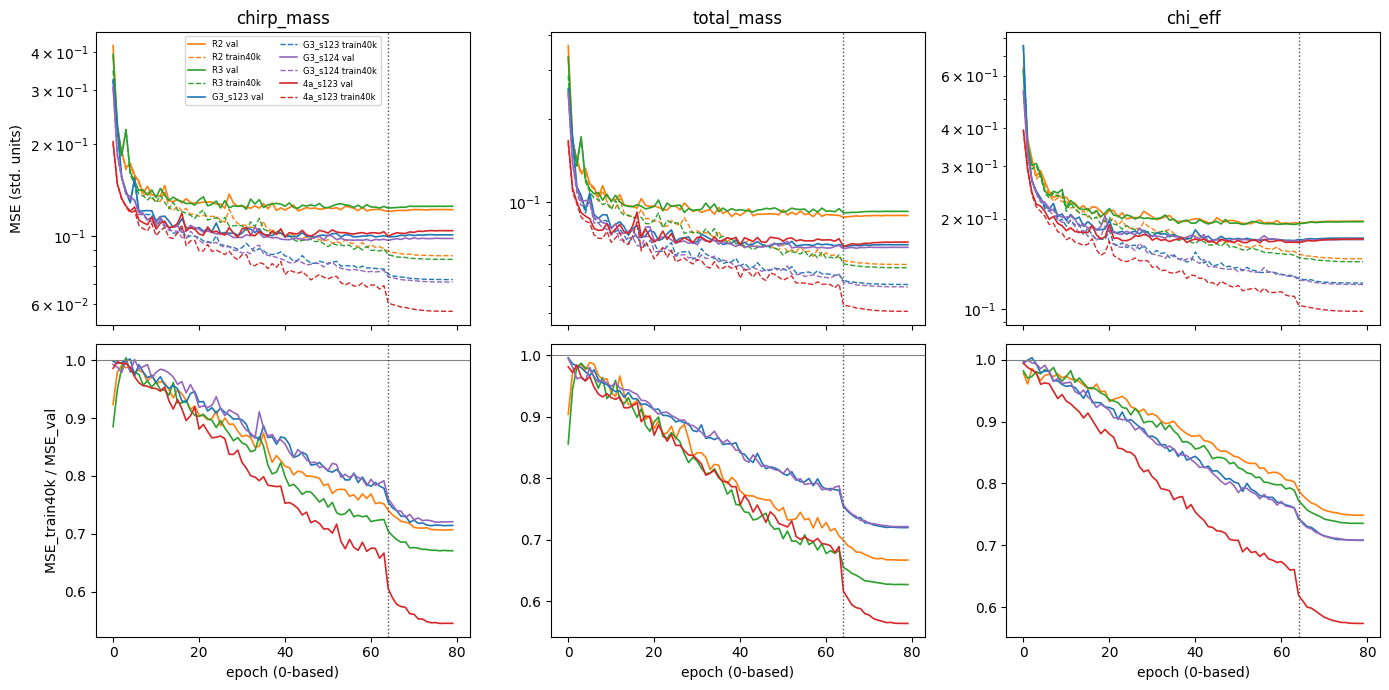

,model,best_val_epoch,best_val_loss,final_epoch,final_val_loss,final_vs_best_pct,first_dropout_off_epoch
0,R2,64,0.13397,79,0.13592,1.4511,64
1,R3,64,0.13581,79,0.13773,1.4159,64
2,G3_s123,62,0.11297,79,0.11448,1.3366,64
3,G3_s124,64,0.11088,79,0.11242,1.3926,64
4,4a_s123,64,0.11195,79,0.11569,3.3403,64


,model,label,val_mse_64,val_mse_79,change_pct,gap_64,gap_79
0,R2,chirp_mass,0.12038,0.12209,1.4255,0.74066,0.70703
1,R2,total_mass,0.088404,0.089651,1.4101,0.69928,0.66707
2,R2,chi_eff,0.19314,0.19601,1.4858,0.78865,0.74861
3,R3,chirp_mass,0.12351,0.12523,1.391,0.7046,0.67079
4,R3,total_mass,0.091689,0.092768,1.1763,0.65498,0.62721
5,R3,chi_eff,0.19222,0.19519,1.5461,0.77234,0.73538
6,G3_s123,chirp_mass,0.099565,0.10099,1.4331,0.75423,0.71444
7,G3_s123,total_mass,0.069619,0.07039,1.1067,0.75391,0.71977
8,G3_s123,chi_eff,0.17015,0.17207,1.1302,0.74257,0.70792
9,G3_s124,chirp_mass,0.096876,0.098266,1.4345,0.76008,0.72088


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for m in NEW:
    h, ep = hist[m], hist[m]['epoch']
    for j in range(3):
        axes[0, j].plot(ep, h['val_mse'][:, j], '-', color=COLORS[m], lw=1.2, label=f'{m} val')
        axes[0, j].plot(ep, h['train40k_mse'][:, j], '--', color=COLORS[m], lw=1.0, label=f'{m} train40k')
        axes[1, j].plot(ep, h['train40k_mse'][:, j] / h['val_mse'][:, j], '-', color=COLORS[m], lw=1.2)
for j, lab in enumerate(LABELS):
    axes[0, j].set(title=lab, yscale='log')
    axes[1, j].axhline(1.0, color='0.5', lw=0.8)
    axes[1, j].set(xlabel='epoch (0-based)')
    for ax in axes[:, j]:
        ax.axvline(EPOCH_MARK, color='0.3', ls=':', lw=1)
axes[0, 0].set_ylabel('MSE (std. units)')
axes[1, 0].set_ylabel('MSE_train40k / MSE_val')
axes[0, 0].legend(fontsize=6, ncol=2)
fig.tight_layout()
plt.show()

rows_best, rows_6479 = [], []
for m in NEW:
    h, ep = hist[m], hist[m]['epoch']
    ib = int(np.argmin(h['val_loss']))
    off = np.flatnonzero(h['dropout_off'].astype(bool))
    rows_best.append(dict(model=m, best_val_epoch=int(ep[ib]), best_val_loss=h['val_loss'][ib],
                          final_epoch=int(ep[-1]), final_val_loss=h['val_loss'][-1],
                          final_vs_best_pct=100.0 * (h['val_loss'][-1] / h['val_loss'][ib] - 1.0),
                          first_dropout_off_epoch=int(ep[off[0]]) if off.size else None))
    i64, i79 = (int(np.flatnonzero(ep == e)[0]) for e in (EPOCH_MARK, EPOCH_END))
    for j, lab in enumerate(LABELS):
        v64, v79 = h['val_mse'][i64, j], h['val_mse'][i79, j]
        rows_6479.append(dict(model=m, label=lab, val_mse_64=v64, val_mse_79=v79,
                              change_pct=100.0 * (v79 / v64 - 1.0),
                              gap_64=h['train40k_mse'][i64, j] / v64, gap_79=h['train40k_mse'][i79, j] / v79))
tab2_best, tab2_6479 = pd.DataFrame(rows_best), pd.DataFrame(rows_6479)
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab2_best)
    display(tab2_6479)

## 3. Banda (G3 frente a G1)
f220 como en M13.1 (`f220_hz`, χ1 = espín de la componente más pesada) a partir de la verdad de val. Clases: <256 (f < 256),
256–512 (256 ≤ f ≤ 512), 512–1024 (512 < f ≤ 1024), >1024 (f > 1024), y además `>512` agrupada (f > 512, definición de M13.1)
usada en la lectura. Bins de M_total: [10,30), [30,50), [50,80), [80,120), [120,180]. Por clase y etiqueta: n, RMSE G1 (media
R2/R3), RMSE G3 (media s123/s124), ΔRMSE% con IC 95 % bootstrap emparejado dentro de la clase (semilla 136002, un único generador
recorrido en el orden de la tabla). Clases con n < 200 se marcan, no se eliminan.

Lectura fijada (sobre M = total_mass y χ_eff; comparación `>512` frente a `<256`): **BANDA** si en M o en χ_eff el ΔRMSE% de
`>512` es más negativo que el de `<256` y sus IC no se solapan; **UNIFORME** si los IC se solapan en ambas etiquetas; otro caso
**MIXTO**. **Descriptivo:** f220 correlaciona fuertemente con la masa, así que no separa banda de masa.

f220 clipped a_f / a_e: 35 0
rows outside M_total bins: 0


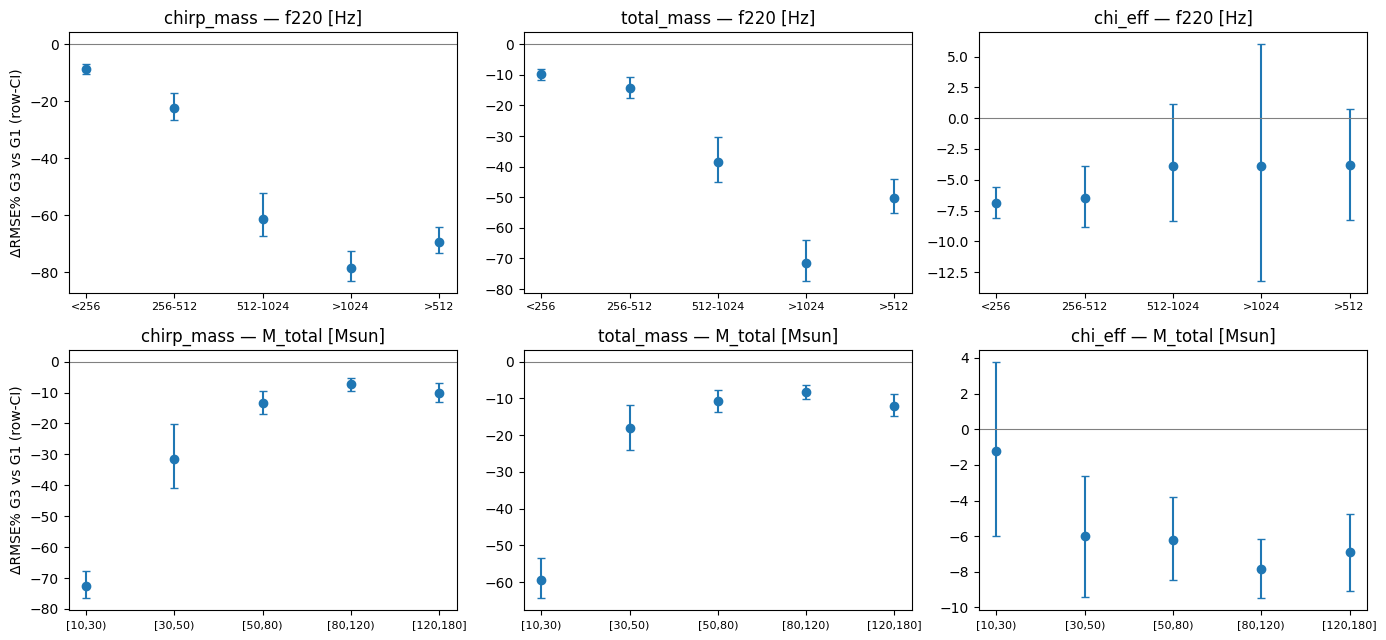

,grouping,cls,label,n,small,rmse_G1,rmse_G3,delta_rmse_pct,ci95_lo_pct,ci95_hi_pct
0,f220,<256,chirp_mass,30680,False,6.4056,5.8501,-8.673,-10.336,-7.0164
1,f220,<256,total_mass,30680,False,10.783,9.7182,-9.8759,-11.621,-8.1371
2,f220,<256,chi_eff,30680,False,0.18587,0.17313,-6.8546,-8.131,-5.6233
3,f220,256-512,chirp_mass,7630,False,2.6651,2.0709,-22.295,-26.62,-17.019
4,f220,256-512,total_mass,7630,False,8.2396,7.0604,-14.312,-17.565,-10.831
5,f220,256-512,chi_eff,7630,False,0.19874,0.18581,-6.5104,-8.8589,-3.8626
6,f220,512-1024,chirp_mass,1490,False,3.2877,1.2769,-61.162,-67.35,-52.127
7,f220,512-1024,total_mass,1490,False,10.776,6.6369,-38.412,-45.123,-30.225
8,f220,512-1024,chi_eff,1490,False,0.28735,0.27627,-3.8555,-8.3465,1.1601
9,f220,>1024,chirp_mass,200,False,9.5804,2.0465,-78.639,-83.039,-72.429


Lectura banda (descriptiva): BANDA


{'total_mass': {'d_gt512': np.float64(-50.14744276666365),
  'ci_gt512': [np.float64(-55.0231316416166), np.float64(-43.90306043725986)],
  'd_lt256': np.float64(-9.875947602439572),
  'ci_lt256': [np.float64(-11.620945438405382), np.float64(-8.13712458897804)],
  'overlap': False,
  'more_negative_gt512': True},
 'chi_eff': {'d_gt512': np.float64(-3.8340808206456467),
  'ci_gt512': [np.float64(-8.295307287058913), np.float64(0.7570835930548412)],
  'd_lt256': np.float64(-6.854574379596523),
  'ci_lt256': [np.float64(-8.130984113273367), np.float64(-5.623283623209876)],
  'overlap': True,
  'more_negative_gt512': False}}

In [5]:
big = m1 >= m2
m_big, m_small = np.where(big, m1, m2), np.where(big, m2, m1)
chi_big, chi_small = np.where(big, s1, s2), np.where(big, s2, s1)
F220, a_f, m_f, n_af_clipped, n_ae_clipped = f220_hz(m_big, m_small, chi_big, chi_small)
check(np.all(np.isfinite(F220) & (F220 > 0)), 'f220 finite and positive')
print('f220 clipped a_f / a_e:', n_af_clipped, n_ae_clipped)

GROUPS = [('f220', '<256', F220 < 256.0), ('f220', '256-512', (F220 >= 256.0) & (F220 <= 512.0)),
          ('f220', '512-1024', (F220 > 512.0) & (F220 <= 1024.0)), ('f220', '>1024', F220 > 1024.0),
          ('f220', '>512', F220 > 512.0)]
for k, (lo, hi) in enumerate(zip(MTOT_EDGES[:-1], MTOT_EDGES[1:])):
    last = k == len(MTOT_EDGES) - 2
    GROUPS.append(('M_total', f'[{lo:g},{hi:g}{"]" if last else ")"}',
                   (MTOT >= lo) & ((MTOT <= hi) if last else (MTOT < hi))))
print('rows outside M_total bins:', int((~np.any([g for gr, _, g in GROUPS if gr == 'M_total'], 0)).sum()))

rng = np.random.default_rng(SEED_BAND)
rows = []
for grouping, cls, g in GROUPS:
    n = int(g.sum())
    if n == 0:
        rows += [dict(grouping=grouping, cls=cls, label=lab, n=0) for lab in LABELS]
        continue
    pt, bt = boot_rmse(G1 + G3, g, N_BOOT, rng)
    d, db = delta_pct(pt, G3, G1), delta_pct(bt, G3, G1)
    lo, hi = np.percentile(db, [2.5, 97.5], axis=0)
    for j, lab in enumerate(LABELS):
        rows.append(dict(grouping=grouping, cls=cls, label=lab, n=n, small=n < MIN_GROUP_N,
                         rmse_G1=np.mean([pt[m][j] for m in G1]), rmse_G3=np.mean([pt[m][j] for m in G3]),
                         delta_rmse_pct=d[j], ci95_lo_pct=lo[j], ci95_hi_pct=hi[j]))
tab3 = pd.DataFrame(rows)


def ci_of(cls, lab):
    r = tab3[(tab3.grouping == 'f220') & (tab3.cls == cls) & (tab3.label == lab)].iloc[0]
    return r.get('delta_rmse_pct', np.nan), r.get('ci95_lo_pct', np.nan), r.get('ci95_hi_pct', np.nan)


band_detail = {}
for lab in ('total_mass', 'chi_eff'):
    (dh, lh, hh), (dl, ll, hl) = ci_of('>512', lab), ci_of('<256', lab)
    overlap = bool(lh <= hl and ll <= hh)
    band_detail[lab] = dict(d_gt512=dh, ci_gt512=[lh, hh], d_lt256=dl, ci_lt256=[ll, hl], overlap=overlap,
                            more_negative_gt512=bool(dh < dl))
if any(not np.isfinite([v['d_gt512'], v['d_lt256']]).all() for v in band_detail.values()):
    reading_band = 'NO EVALUABLE'
elif any(v['more_negative_gt512'] and not v['overlap'] for v in band_detail.values()):
    reading_band = 'BANDA'
elif all(v['overlap'] for v in band_detail.values()):
    reading_band = 'UNIFORME'
else:
    reading_band = 'MIXTO'

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for i, grouping in enumerate(('f220', 'M_total')):
    for j, lab in enumerate(LABELS):
        t = tab3[(tab3.grouping == grouping) & (tab3.label == lab) & (tab3.n > 0)]
        x = np.arange(len(t))
        ax = axes[i, j]
        ax.errorbar(x, t.delta_rmse_pct, yerr=[t.delta_rmse_pct - t.ci95_lo_pct, t.ci95_hi_pct - t.delta_rmse_pct],
                    fmt='o', color=COLORS['G3'], capsize=3)
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(t.cls, fontsize=8)
        ax.set(title=f'{lab} — {grouping}' + (' [Hz]' if grouping == 'f220' else ' [Msun]'))
    axes[i, 0].set_ylabel('ΔRMSE% G3 vs G1 (row-CI)')
fig.tight_layout()
plt.show()
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab3)
print('Lectura banda (descriptiva):', reading_band)
band_detail

## 4. HIP-CONTEXTO (M13.4a)
τ30 newtoniano a partir de la M_c verdadera y deciles exactamente como en M13.1 (D1 = τ más corto, D10 = más largo). Por decil:
ΔRMSE% = 100·(RMSE_4a / media RMSE 3b − 1) con IC 95 % bootstrap emparejado dentro del decil (semilla 136003). Contraste:
media de D8–D10 menos media de D1–D3 de ΔRMSE% de χ_eff; su distribución bootstrap combina las réplicas independientes de cada
decil. Lectura: **APOYA** si la diferencia es negativa y su IC excluye 0; si no, **NO APOYA**.

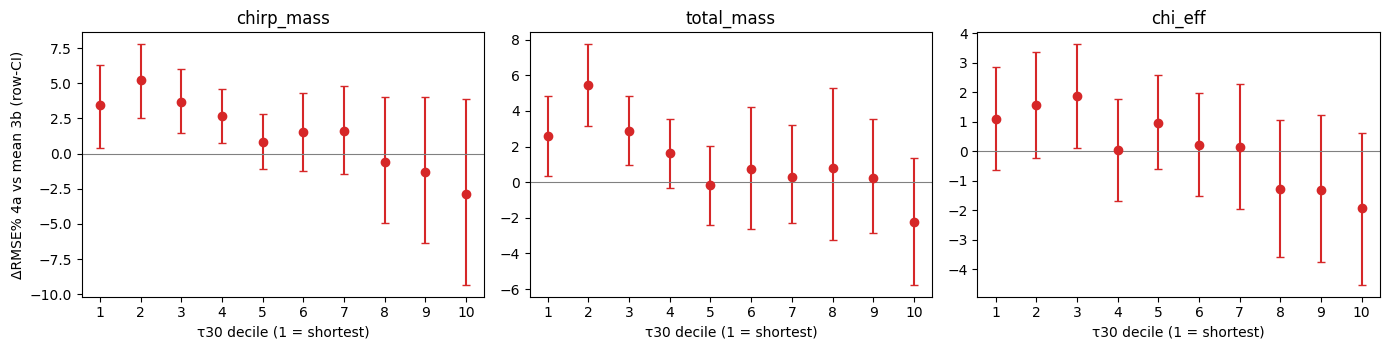

,label,tau_decile,tau_lo_s,tau_hi_s,n,rmse_4a,rmse_3b,delta_rmse_pct,ci95_lo_pct,ci95_hi_pct
2,chi_eff,1,0.052278,0.078744,4000,0.19515,0.19305,1.0855,-0.65096,2.8514
5,chi_eff,2,0.078744,0.099333,4000,0.18518,0.18232,1.5705,-0.24087,3.3619
8,chi_eff,3,0.099333,0.1223,4000,0.17646,0.1732,1.8815,0.1054,3.62
11,chi_eff,4,0.1223,0.15126,4000,0.16693,0.16684,0.050082,-1.6766,1.7598
14,chi_eff,5,0.15126,0.1894,4000,0.166,0.1644,0.96916,-0.60264,2.5918
17,chi_eff,6,0.1894,0.24407,4000,0.15775,0.1574,0.22014,-1.5082,1.9855
20,chi_eff,7,0.24407,0.3249,4000,0.16104,0.1608,0.1497,-1.9556,2.2892
23,chi_eff,8,0.3249,0.45347,4000,0.16378,0.16589,-1.2688,-3.6056,1.0478
26,chi_eff,9,0.45347,0.70688,4000,0.17527,0.17762,-1.3207,-3.7753,1.2351
29,chi_eff,10,0.70688,5.8918,4000,0.25319,0.25819,-1.9365,-4.5291,0.60311


chi_eff: mean(D8-D10) - mean(D1-D3) = -3.021 % [-4.68, -1.29] -> APOYA


In [6]:
tau30 = tau_newtonian(Y[:, 0])
tau_edges = np.quantile(tau30, np.linspace(0, 1, 11))
tdec = np.clip(np.searchsorted(tau_edges[1:-1], tau30, side='right'), 0, 9)
rng = np.random.default_rng(SEED_TAU)
rows, dboot = [], np.empty((10, N_BOOT, 3))
for d in range(10):
    g = tdec == d
    pt, bt = boot_rmse(G3 + [H4A], g, N_BOOT, rng)
    dp, dboot[d] = delta_pct(pt, [H4A], G3), delta_pct(bt, [H4A], G3)
    lo, hi = np.percentile(dboot[d], [2.5, 97.5], axis=0)
    for j, lab in enumerate(LABELS):
        rows.append(dict(label=lab, tau_decile=d + 1, tau_lo_s=tau_edges[d], tau_hi_s=tau_edges[d + 1], n=int(g.sum()),
                         rmse_4a=pt[H4A][j], rmse_3b=np.mean([pt[m][j] for m in G3]),
                         delta_rmse_pct=dp[j], ci95_lo_pct=lo[j], ci95_hi_pct=hi[j]))
tab4 = pd.DataFrame(rows)

J = LABELS.index('chi_eff')
LONG, SHORT = [7, 8, 9], [0, 1, 2]
d_chi = tab4[tab4.label == 'chi_eff'].sort_values('tau_decile').delta_rmse_pct.to_numpy()
ctx_diff = d_chi[LONG].mean() - d_chi[SHORT].mean()
ctx_lo, ctx_hi = np.percentile(dboot[LONG, :, J].mean(0) - dboot[SHORT, :, J].mean(0), [2.5, 97.5])
reading_ctx = 'APOYA' if (ctx_diff < 0 and ctx_hi < 0) else 'NO APOYA'

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
x = np.arange(1, 11)
for ax, lab in zip(axes, LABELS):
    t = tab4[tab4.label == lab]
    ax.errorbar(x, t.delta_rmse_pct, yerr=[t.delta_rmse_pct - t.ci95_lo_pct, t.ci95_hi_pct - t.delta_rmse_pct],
                fmt='o', color=COLORS[H4A], capsize=3)
    ax.axhline(0, color='0.5', lw=0.8)
    ax.set(title=lab, xlabel='τ30 decile (1 = shortest)', xticks=x)
axes[0].set_ylabel('ΔRMSE% 4a vs mean 3b (row-CI)')
fig.tight_layout()
plt.show()
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab4[tab4.label == 'chi_eff'])
print(f'chi_eff: mean(D8-D10) - mean(D1-D3) = {ctx_diff:.4g} % [{ctx_lo:.4g}, {ctx_hi:.4g}] -> {reading_ctx}')

## 5. Colas y SNR
Sesgo con signo (media de f − θ) y RMSE por decil de θ verdadero (bordes de val, comunes), y RMSE por 5 bins de SNR de igual
anchura en [10, 25] (último cerrado; SNR = `target_network_snr` del HDF5 G3), para M11, media G1 (R2/R3) y media G3 (s123/s124).
Media de las métricas por modelo. Descriptivo.

rows outside SNR range: 0


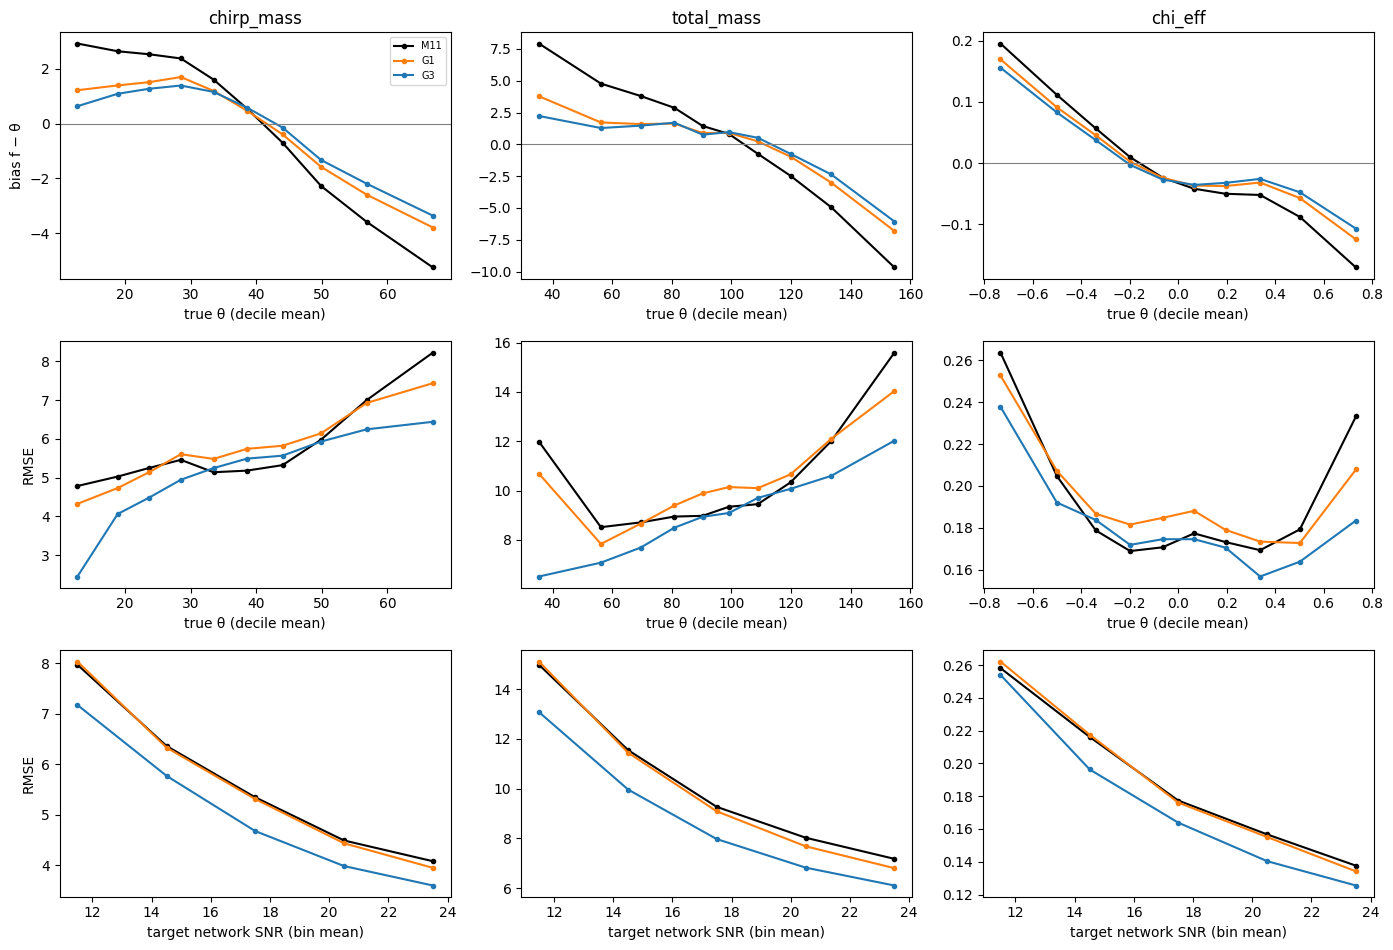

,set,snr_bin,snr_center,n,chirp_mass,total_mass,chi_eff
0,M11,"[10,13)",11.496,8084,7.9719,14.979,0.25814
1,M11,"[13,16)",14.51,8021,6.3588,11.545,0.21614
2,M11,"[16,19)",17.499,7945,5.3433,9.2704,0.17734
3,M11,"[19,22)",20.502,8073,4.4872,8.0306,0.15668
4,M11,"[22,25]",23.503,7877,4.0759,7.1808,0.13758
5,G1,"[10,13)",11.496,8084,8.0339,15.105,0.26213
6,G1,"[13,16)",14.51,8021,6.3269,11.442,0.21749
7,G1,"[16,19)",17.499,7945,5.3089,9.0926,0.1761
8,G1,"[19,22)",20.502,8073,4.4317,7.6855,0.15507
9,G1,"[22,25]",23.503,7877,3.9444,6.8063,0.13411


In [7]:
SETS = {'M11': ['M11'], 'G1': G1, 'G3': G3}
rows = []
for j, lab in enumerate(LABELS):
    edges = np.quantile(Y[:, j], np.linspace(0, 1, 11))
    dec = np.clip(np.searchsorted(edges[1:-1], Y[:, j], side='right'), 0, 9)
    for s, ms in SETS.items():
        for k in range(10):
            g = dec == k
            r = [P[m][g, j] - Y[g, j] for m in ms]
            rows.append(dict(set=s, label=lab, decile=k + 1, center=Y[g, j].mean(), n=int(g.sum()),
                             bias=np.mean([x.mean() for x in r]), rmse=np.mean([np.sqrt(np.mean(x**2)) for x in r])))
tab5_dec = pd.DataFrame(rows)

sbin = np.searchsorted(SNR_EDGES[1:-1], SNR, side='right')
in_range = (SNR >= SNR_EDGES[0]) & (SNR <= SNR_EDGES[-1])
print('rows outside SNR range:', int((~in_range).sum()))
rows = []
for s, ms in SETS.items():
    for b in range(len(SNR_EDGES) - 1):
        g = in_range & (sbin == b)
        rmse_b = np.mean([np.sqrt(np.mean((P[m][g] - Y[g])**2, axis=0)) for m in ms], 0)
        rows.append(dict(set=s, snr_bin=f'[{SNR_EDGES[b]:g},{SNR_EDGES[b + 1]:g}{"]" if b == 4 else ")"}',
                         snr_center=SNR[g].mean(), n=int(g.sum()), **dict(zip(LABELS, rmse_b))))
tab5_snr = pd.DataFrame(rows)

fig, axes = plt.subplots(3, 3, figsize=(14, 9.6))
for j, lab in enumerate(LABELS):
    for s in SETS:
        t = tab5_dec[(tab5_dec.set == s) & (tab5_dec.label == lab)]
        axes[0, j].plot(t.center, t.bias, 'o-', ms=3, color=COLORS[s], label=s)
        axes[1, j].plot(t.center, t.rmse, 'o-', ms=3, color=COLORS[s])
        t = tab5_snr[tab5_snr.set == s]
        axes[2, j].plot(t.snr_center, t[lab], 'o-', ms=3, color=COLORS[s])
    axes[0, j].axhline(0, color='0.5', lw=0.8)
    axes[0, j].set(title=lab, xlabel='true θ (decile mean)')
    axes[1, j].set(xlabel='true θ (decile mean)')
    axes[2, j].set(xlabel='target network SNR (bin mean)')
axes[0, 0].set_ylabel('bias f − θ')
axes[1, 0].set_ylabel('RMSE')
axes[2, 0].set_ylabel('RMSE')
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab5_snr)

## 6. C3 (ridge sobre el embedding), protocolo M12.5.3
Idéntico a M13_3a (`ridge_paths`, `select_inner`): ridge sobre θ − f con entradas [emb, f], α ∈ {1e-2, …, 1e4} por etiqueta por LOEO
interno; LOEO externo por `file_group_id` (del HDF5 G3). Bootstrap pareado dentro de entorno (2000, semilla 125301), intervalo al
99,5833 % y margen del 1 %. Fracción de riesgo evitable = (MSE_modelo − MSE_C3)/MSE_modelo, para M13_3b_G3_s123 y s124.
Exploratorio, ajustado en val.

In [8]:
def c3_loeo(f, y, emb, env):
    """Out-of-fold C3 predictions; identical to the C3 branch of m12_5_3 loeo_predictions."""
    z, r = np.hstack([emb, f]), y - f
    out, chosen = np.empty_like(y), []
    for e in np.unique(env):
        te, tr = env == e, env != e
        best, _ = select_inner(ridge_paths, z[tr], r[tr], env[tr])
        outer = ridge_paths(z[tr], r[tr], z[te])
        out[te] = f[te] + np.stack([outer[best[j], :, j] for j in range(len(LABELS))], 1)
        chosen.append(dict(heldout_env=str(e), **{lab: ALPHAS[best[j]] for j, lab in enumerate(LABELS)}))
    return out, chosen


rows, c3_alphas = [], {}
q_lo, q_hi = 100 * FAMILY_ALPHA / 2, 100 * (1 - FAMILY_ALPHA / 2)
for m in G3:
    pc, c3_alphas[m] = c3_loeo(P[m], Y, EMB[m], ENV)
    e_m, e_c = (P[m] - Y)**2, (pc - Y)**2
    bm = bootstrap_means(e_m - e_c, ENV, {'global': np.ones(len(Y), bool)}, C3_N_BOOT, C3_SEED)['global']
    lo, hi = np.percentile(bm, [q_lo, q_hi], axis=0)
    for j, lab in enumerate(LABELS):
        mse_m, mse_c = e_m[:, j].mean(), e_c[:, j].mean()
        rows.append(dict(model=m, label=lab, mse_model=mse_m, mse_c3=mse_c, avoidable_frac=(mse_m - mse_c) / mse_m,
                         d_lo=lo[j], d_hi=hi[j], margin=MARGIN_FRAC * mse_m,
                         decision=decide(lo[j], hi[j], MARGIN_FRAC * mse_m)))
    print(f'{m} done', flush=True)
tab6 = pd.DataFrame(rows)
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab6)

G3_s123 done
G3_s124 done


,model,label,mse_model,mse_c3,avoidable_frac,d_lo,d_hi,margin,decision
0,G3_s123,chirp_mass,27.522,27.232,0.010536,0.15809,0.43663,0.27522,UNRESOLVED
1,G3_s123,total_mass,84.772,84.087,0.0080788,0.29785,1.0729,0.84772,UNRESOLVED
2,G3_s123,chi_eff,0.033364,0.032943,0.012621,0.00023179,0.0005859,0.00033364,UNRESOLVED
3,G3_s124,chirp_mass,26.779,26.512,0.0099738,0.14371,0.38672,0.26779,UNRESOLVED
4,G3_s124,total_mass,82.948,82.376,0.0068965,0.25662,0.88026,0.82948,UNRESOLVED
5,G3_s124,chi_eff,0.032985,0.032614,0.011247,0.00021762,0.00054555,0.00032985,UNRESOLVED


## 7. Resumen

In [9]:
def to_json(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


def by_label(t):
    return {r['label']: {k: r[k] for k in ('delta_rmse_pct', 'ci95_lo_pct', 'ci95_hi_pct', 'noise_used_pct', 'resolved')}
            for r in t.to_dict('records')}


summary = dict(
    experiment='M13.3b / M13.4a evaluation (val only)',
    inputs={k: dict(path=str(p), sha256=sha[k]) for k, p in files.items()},
    g3_hdf5=dict(path=str(G3_H5), columns=META, rows='val only'),
    contract_identity=identity,
    checks=checks,
    settings=dict(labels=LABELS, residual='f - theta', units='physical (train-only M11 scaler)', tags=TAGS,
                  g1_pair=G1, g3_pair=G3, h4a=H4A, n_boot=N_BOOT,
                  seeds=dict(global_rows=SEED_GLOBAL, band=SEED_BAND, tau=SEED_TAU, c3=C3_SEED),
                  bootstrap='paired row resampling of val: row sampling, not seed variation',
                  epoch_mark=EPOCH_MARK, epoch_end=EPOCH_END, c3_alphas=ALPHAS, c3_n_boot=C3_N_BOOT,
                  c3_family_alpha=FAMILY_ALPHA, c3_margin_frac=MARGIN_FRAC, snr_edges=SNR_EDGES,
                  mtot_edges=MTOT_EDGES, min_group_n_flag=MIN_GROUP_N,
                  f220_classes='<256: f<256; 256-512: 256<=f<=512; 512-1024: 512<f<=1024; >1024: f>1024; '
                               '>512 (pooled, reading): f>512',
                  tau_deciles='tau30 Newtonian from true Mc, val quantile edges (M13.1)',
                  same_train40k_idx_as_R2=same_tr40, n_val=len(Y), n_envs=len(np.unique(ENV))),
    metrics=tab1.to_dict('records'),
    comparisons=tab1_cmp.to_dict('records'),
    dynamics_best_vs_final=tab2_best.to_dict('records'),
    dynamics_val_64_79=tab2_6479.to_dict('records'),
    band=tab3.to_dict('records'),
    band_detail=band_detail,
    tau_deciles=tab4.to_dict('records'),
    tau_edges_s=tau_edges,
    tails_deciles=tab5_dec.to_dict('records'),
    snr=tab5_snr.to_dict('records'),
    c3=tab6.to_dict('records'),
    c3_alphas=c3_alphas,
    readings=dict(
        G3_vs_G1=by_label(tab1_cmp[tab1_cmp.comparison == 'G3_vs_G1']),
        M13_4a_vs_3b=by_label(tab1_cmp[tab1_cmp.comparison == '4a_vs_3b']),
        band=dict(reading=reading_band, descriptive=True, note='f220 correlates with mass'),
        hip_contexto=dict(reading=reading_ctx, chi_eff_long_minus_short_pct=ctx_diff,
                          ci95=[ctx_lo, ctx_hi], long=['D8', 'D9', 'D10'], short=['D1', 'D2', 'D3']),
        c3_avoidable_frac={m: dict(zip(tab6[tab6.model == m].label, tab6[tab6.model == m].avoidable_frac)) for m in G3},
        best_val_epoch={r['model']: dict(best=r['best_val_epoch'], final=r['final_epoch']) for r in rows_best}),
)
with open(SUMMARY_PATH, 'x') as fh:
    json.dump(summary, fh, indent=1, default=to_json)
print('saved', SUMMARY_PATH)
summary['readings']

saved /data/vserrano/cbc_pe_data/results/M13_3/M13_3b_4a_evaluation_summary.json


{'G3_vs_G1': {'chirp_mass': {'delta_rmse_pct': -10.24209568412383,
   'ci95_lo_pct': -11.872803579167693,
   'ci95_hi_pct': -8.653837320969732,
   'noise_used_pct': 1.3680854077194948,
   'resolved': True},
  'total_mass': {'delta_rmse_pct': -12.623022021613961,
   'ci95_lo_pct': -14.214762885696226,
   'ci95_hi_pct': -11.06947695326039,
   'noise_used_pct': 1.7087929828877504,
   'resolved': True},
  'chi_eff': {'delta_rmse_pct': -6.474913969465779,
   'ci95_lo_pct': -7.542454356445179,
   'ci95_hi_pct': -5.394938958918887,
   'noise_used_pct': 0.5707886984499687,
   'resolved': True}},
 'M13_4a_vs_3b': {'chirp_mass': {'delta_rmse_pct': 2.2746756750215757,
   'ci95_lo_pct': 1.27952858827182,
   'ci95_hi_pct': 3.3344840891997736,
   'noise_used_pct': 1.3680854077194948,
   'resolved': False},
  'total_mass': {'delta_rmse_pct': 1.6504027849103986,
   'ci95_lo_pct': 0.7444099631245821,
   'ci95_hi_pct': 2.555251494585654,
   'noise_used_pct': 1.087144153941524,
   'resolved': False},
  '

## Conclusiones M13.3b / M13.4a (28-10-2026)

**Verificado (val, 40 000 filas emparejadas por fuente; ruido de semilla con 2 semillas por dataset; IC de bootstrap = muestreo de filas)**

1. **G3 mejora frente a G1 de forma resuelta:** ΔRMSE −10,2 % [−11,9; −8,7] (M_c), −12,6 % [−14,2; −11,1] (M),
   −6,5 % [−7,5; −5,4] (χ_eff), entre 4 y 11 veces el ruido de semilla (≤ 1,7 %). La mejora aparece en todos los bins de SNR
   (−10 a −13 %) y reduce aún más el sesgo en las colas (Q10 de M_c: +1,2 → +0,6 M☉; Q10 de M: +3,7 → +2,2 M☉).
   El efecto de G3 es un paquete (banda, filtro, realización de ruido y banda de SNR) y no se atribuye a una sola parte.
2. **Dos componentes (descriptivo; f₂₂₀ y M están ligadas):**
   - **Sistemas ligeros** (f₂₂₀ > 512 Hz o M < 30 M☉, ~4 % de val): M_c −61 a −79 %, M −38 a −72 %. Coherente con
     recuperar la fusión y el ringdown que G1 cortaba a 512 Hz.
   - **Sistemas pesados** (f₂₂₀ < 256 Hz, M ≥ 80 M☉): −7 a −12 % en las tres etiquetas. Su señal ya estaba en la banda de G1,
     así que esta parte no puede atribuirse a la banda; es compatible con HIP-LÍNEAS (blanqueado de 16 s). No demostrado.
   - χ_eff mejora −6 a −8 % de forma casi uniforme y **no** más en los ligeros (−3,8 %, IC con 0), coherente con que
     χ_eff se mide sobre todo en la fase del inspiral.
3. **C3 en G3:** riesgo evitable 0,7–1,3 % (sin resolver), frente a 1,5–3 % en G1. El estimador está prácticamente en el
   óptimo de su embedding.
4. **M13.4a (agregación por transformer):** global sin resolver (+2,3 / +1,7 / −0,05 %; ruido de semilla 1,4 / 1,1 / 0,6 %).
   **Patrón de HIP-CONTEXTO confirmado:** χ_eff mejora en los τ largos (D8–D10) y empeora en los cortos (D1–D3);
   diferencia −3,0 % [−4,7; −1,3]. Una sola semilla: el IC no incluye la variación entre semillas.
5. **Sobreajuste:** en los 5 modelos, la mejor val está en las épocas 62–64 y la final es un 1,1–1,5 % peor (3,3 % en 4a).
   La pendiente ya queda corregida en la primera época sin dropout. La brecha MSE_train40k/MSE_val es ≈ 0,71 en G1 y en G3,
   y 0,55–0,57 en 4a.

**Hipótesis (sin verificar)**
- La ganancia de contexto global de 4a queda anulada por su mayor sobreajuste: en la época 64 su val es igual a la de 3b.
- La brecha train/val no cambia con el blanqueado: inclina hacia memorización del ruido fijo (HIP-RUIDO-FIJO) frente a
  cambio de entorno. Lo decide M13.5.
- Una fase sin dropout de 2–4 épocas corregiría la pendiente sin el coste de val (+1,1–1,5 % MSE). Pospuesto hasta M13.5.

**Decisión:** G3 pasa a ser el dataset de producción y M13.3b (G3, procedimiento de R2) la base. M13.4a no se adopta.
HIP-CONTEXTO queda apoyada como patrón y se reevaluará en el régimen que resulte de M13.5 (aumentación de ruido si se
confirma HIP-RUIDO-FIJO). M13.4b, pendiente de rediseño (checkpointing), en el mismo régimen.